# Prebuilt robots

ARIEL ships a set of ready-made robot bodies: 13 from John's set (baby, gecko, snake, turtle, iguana, three spiders, three centipedes and more), plus a plain spider, a random 20-module spider and two spiders with blocks. Each is a function that returns a `CoreModule`, the root of a tree of body parts.

In this notebook you build all 17, drop each one into a flat world, compare their size in a table and a chart, let each fall and settle for one second with no control, and check that nothing blows up. If this machine has a working OpenGL backend the last section also renders every robot; without one it says so and the rest still runs.

In [1]:
# Standard library
from pathlib import Path

In [2]:
# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from rich.table import Table

In [3]:
# Local libraries
from ariel import console
from ariel.body_phenotypes.robogen_lite.prebuilt_robots import (
    john_set,
    random_20,
    spider,
    spider_with_blocks,
)
from ariel.simulation import SimpleFlatWorld

In [4]:
# Settings (nothing here is random: the random spider has its own fixed seed)
ROBOTS = 17  # 13 from John's set plus 4 others
SETTLE_STEPS = 400
RENDER_SIZE = 240
DATA = Path.cwd() / "__data__" / "prebuilt_robots"
DATA.mkdir(parents=True, exist_ok=True)

## Build every robot

A builder takes no arguments and returns a new `CoreModule` each time. `spec` holds the MuJoCo description of the whole body.

In [5]:
builders = {
    name: getattr(john_set, name)
    for name in (
        "baby_a",
        "baby_b",
        "gecko",
        "linkin_modified",
        "snake",
        "turtle",
        "iguana",
        "spider_8",
        "spider_12",
        "spider_16",
        "centipede_3",
        "centipede_4",
        "centipede_5",
    )
}
builders["spider"] = spider.spider
builders["random_spider20"] = random_20.random_spider20
builders["body_spider"] = spider_with_blocks.body_spider
builders["body_spider45"] = spider_with_blocks.body_spider45
console.print(f"{len(builders)} robots")
assert len(builders) == ROBOTS

17 robots

## Drop each one into a flat world

`SimpleFlatWorld.spawn` adds the body to the world. After compiling, the model tells us how many bodies, geoms and actuators the robot has and how much it weighs. Then we step the physics for a short time with no control and keep the data.

In [6]:
models = {}
settled = {}
for name, build in builders.items():
    world = SimpleFlatWorld(load_precompiled=False)
    world.spawn(build().spec)
    model = world.spec.compile()
    data = mujoco.MjData(model)
    for _ in range(SETTLE_STEPS):
        mujoco.mj_step(model, data)
    models[name] = model
    settled[name] = data

In [7]:
table = Table(title="Prebuilt robots")
for column in (
    "robot",
    "bodies",
    "geoms",
    "actuators",
    "mass (kg)",
    "core height (m)",
):
    table.add_column(column, justify="right" if column != "robot" else "left")
for name, model in models.items():
    table.add_row(
        name,
        str(model.nbody),
        str(model.ngeom),
        str(model.nu),
        f"{model.body_mass.sum():.2f}",
        f"{settled[name].qpos[2]:.3f}",
    )
console.print(table)

                               Prebuilt robots                                
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ robot           ┃ bodies ┃ geoms ┃ actuators ┃ mass (kg) ┃ core height (m) ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ baby_a          │     35 │    25 │         8 │      2.35 │           0.100 │
│ baby_b          │     44 │    32 │        10 │      2.75 │           0.100 │
│ gecko           │     28 │    20 │         6 │      2.05 │           0.100 │
│ linkin_modified │     43 │    29 │        12 │      2.61 │           0.100 │
│ snake           │     35 │    25 │         8 │      2.34 │           0.100 │
│ turtle          │     49 │    34 │        13 │      2.89 │           0.100 │
│ iguana          │     34 │    24 │         8 │      2.29 │           0.100 │
│ spider_8        │     36 │    26 │         8 │      2.40 │           0.100 │
│ spider_12       │     52 │    38 │        12 │      3.10 │           0.100 │
│ spider_16       │     68 │    50 │        16 │      3.80 │           0.100 │
│ centipede_3     │     48 │    35 │        11 │      2.92 │           0.100 │
│ centipede_4     │     60 │    44 │        14 │      3.45 │           0.100 │
│ centipede_5     │     72 │    53 │        17 │      3.97 │           0.100 │
│ spider          │     32 │    22 │         8 │      2.18 │           0.100 │
│ random_spider20 │     41 │    30 │         9 │      2.63 │           0.130 │
│ body_spider     │     36 │    26 │         8 │      2.40 │           0.100 │
│ body_spider45   │     36 │    26 │         8 │      2.40 │           0.100 │
└─────────────────┴────────┴───────┴───────────┴───────────┴─────────────────┘

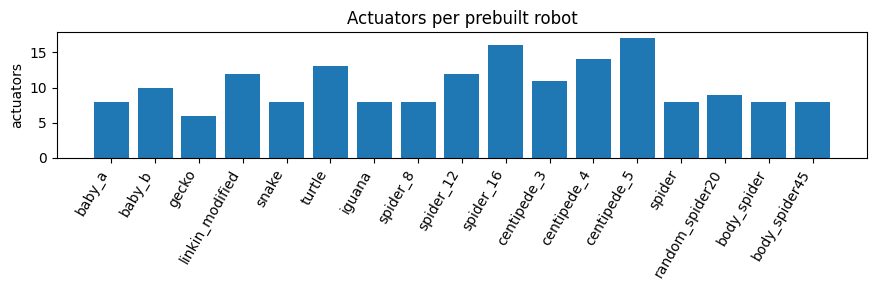

In [8]:
fig, axis = plt.subplots(figsize=(9, 3))
axis.bar(list(models), [m.nu for m in models.values()])
axis.set_ylabel("actuators")
axis.set_title("Actuators per prebuilt robot")
plt.setp(axis.get_xticklabels(), rotation=60, ha="right")
plt.tight_layout()
plt.show()

## Checks

Every robot must have actuators and mass, and after settling its state must be finite (no NaN) with the core above the floor. The spiders and centipedes come in sizes, so their actuator counts must grow with the size in the name.

In [9]:
for name, model in models.items():
    assert model.nu > 0, name
    assert model.body_mass.sum() > 0, name
    assert np.isfinite(settled[name].qpos).all(), name
    assert settled[name].qpos[2] > 0, name  # core above the floor
spiders = [models[n].nu for n in ("spider_8", "spider_12", "spider_16")]
centipedes = [
    models[n].nu for n in ("centipede_3", "centipede_4", "centipede_5")
]
assert spiders == sorted(spiders)
assert centipedes == sorted(centipedes)

## Look at them (needs OpenGL)

Rendering needs a working OpenGL backend. The first cell tries to open a tiny render context. If it fails, the next cell prints a message instead of pictures.

In [10]:
try:
    mujoco.Renderer(mujoco.MjModel.from_xml_string("<mujoco/>"), 8, 8).close()
    OPENGL = True
except mujoco.FatalError:
    OPENGL = False
console.print(f"OpenGL works: {OPENGL}")

/home/jmdm/projects/ariel/.venv/lib/python3.12/site-packages/glfw/__init__.py:917: GLFWError: (65550) b'X11: The DISPLAY environment variable is missing'
  warnings.warn(message, GLFWError)
/home/jmdm/projects/ariel/.venv/lib/python3.12/site-packages/glfw/__init__.py:917: GLFWError: (65537) b'The GLFW library is not initialized'
  warnings.warn(message, GLFWError)


OpenGL works: False

In [11]:
if OPENGL:
    columns = 6
    rows = -(-len(models) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(2.2 * columns, 2.4 * rows))
    for axis in axes.flat:
        axis.axis("off")
    for axis, (name, model) in zip(axes.flat, models.items(), strict=False):
        with mujoco.Renderer(model, RENDER_SIZE, RENDER_SIZE) as renderer:
            renderer.update_scene(settled[name])
            picture = renderer.render()
        assert picture.std() > 0, name  # not one flat colour
        axis.imshow(picture)
        axis.set_title(name, fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    console.print("No working OpenGL backend: skipped the pictures.")

No working OpenGL backend: skipped the pictures.